# Proyecto final BI — Análisis de inversionistas (entrega corregida)
**Rol:** Analista de inversionistas · Crunchbase · Universidad del Istmo

**Pregunta de negocio:** ¿Qué inversionistas son más activos y cuáles tienen mejores
tasas de salida, una vez comparados con sus pares? ¿Cambia el Top 10 si cambiamos
la definición de éxito?

**Entregables del PDF:** métricas de actividad, dos definiciones de éxito,
benchmark, ranking y sensibilidad, tamaño mínimo de portafolio justificado,
resultados reproducibles en `marts.res_*`, interpretación y limitaciones.

**Integración:** usa únicamente las tablas oficiales `marts` creadas por
`run_all.py`; no modifica los hechos ni las dimensiones del equipo.


## 1. Fuentes, supuestos y criterios

- **Fuente:** `marts.puente_ronda_inversionista`, `marts.fact_rondas`,
  `marts.dim_inversionista`, `marts.dim_empresa` y `marts.met_salida_empresa`.
- **Cobertura:** 2005–2013; el histórico previo a 2005 es escaso.
- **Actividad:** al menos una ronda en 2005–2013.
- **Portafolio:** empresas distintas, no número de participaciones ni de rondas.
- **V1:** proporción de empresas con adquisición o IPO observada después de la
  primera inversión y hasta 2013-12-31.
- **V2:** proporción con salida dentro de cinco años; solo primeras inversiones
  hasta 2008-12-31 para asegurar cinco años de observación.
- **Benchmark:** promedio de tasas de salida de otros inversionistas que
  participan en la misma industria, etapa y cohorte de primera inversión;
  el inversionista evaluado se excluye completamente de sus pares.
- **Umbral principal:** cinco empresas elegibles para ambas versiones;
  se contrastan umbrales 1, 3, 5, 10 y 20.
- **Dinero atribuido:** `monto_usd × peso` del puente es una distribución
  contable, **no** capital efectivamente aportado por cada inversionista.

El ranking V1/V2 se compara sobre un **universo común** de inversionistas para
evitar que las coincidencias cambien solo por denominadores no comparables.


In [1]:
from pathlib import Path
import duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'run_all.py').exists()), None)
if ROOT is None: raise FileNotFoundError('Abrí Jupyter desde la carpeta del repositorio que contiene run_all.py')
DB = ROOT/'data'/'crunchbase.duckdb'
if not DB.exists(): raise FileNotFoundError(f'Falta {DB}. Ejecutá primero run_all.py')
con = duckdb.connect(str(DB))
INICIO, CORTE, INICIO_ACTIVO = '2005-01-01', '2013-12-31', '2011-01-01'
MIN_PORTAFOLIO = 5
requeridas = {
 'puente_ronda_inversionista': {'ronda_id','inversionista_id','peso'},
 'fact_rondas': {'ronda_id','empresa_id','fecha','monto_usd'},
 'dim_inversionista': {'inversionista_id','nombre','tipo_inversionista','pais'},
 'dim_empresa': {'empresa_id','industria','etapa'},
 'met_salida_empresa': {'empresa_id','fecha_primera_salida'}
}
for tabla, necesarias in requeridas.items():
    disponibles = {r[0] for r in con.execute(f'DESCRIBE marts.{tabla}').fetchall()}
    if faltan := necesarias-disponibles: raise ValueError(f'marts.{tabla}: faltan {sorted(faltan)}')
print('Base validada:',DB)
print('Tablas marts:', con.execute("SELECT COUNT(*) FROM information_schema.tables WHERE table_schema='marts'").fetchone()[0])

Base validada: /Users/robertomejia/Proyectos/crunchbase-bi-proyecto-final/data/crunchbase.duckdb
Tablas marts: 21


## 2. Exploración de cobertura y calidad

Cobertura anual; los años previos a 2005 se muestran solo como diagnóstico


,anio,rondas,empresas,rondas_con_monto,financiamiento_usd
10,1994,2,2,2,1.340000e+07
11,1995,7,6,5,1.730000e+07
12,1996,7,7,4,1.354250e+07
13,1997,9,9,8,6.462000e+07
14,1998,29,26,16,1.531390e+08
15,1999,76,63,60,5.639384e+08
16,2000,125,117,104,1.435689e+09
17,2001,96,87,74,8.411058e+08
18,2002,116,114,96,9.089987e+08
19,2003,159,152,133,9.102829e+08


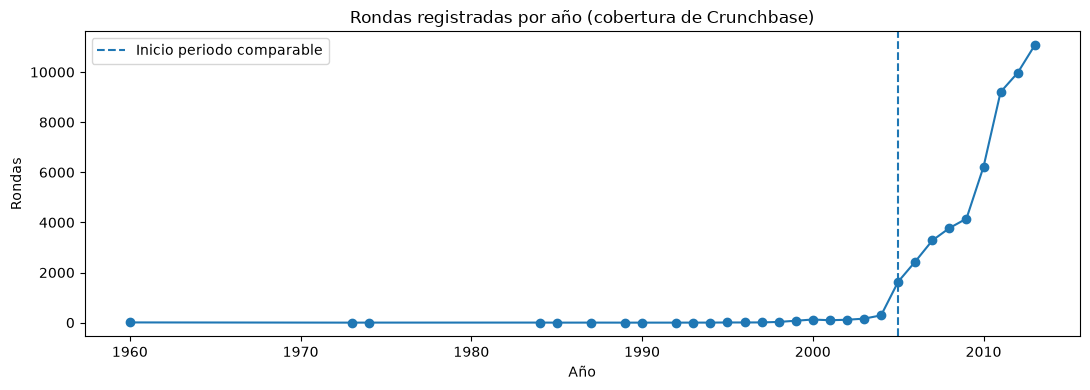

In [2]:
cobertura = con.execute("""SELECT YEAR(fecha) anio, COUNT(DISTINCT ronda_id) rondas,
COUNT(DISTINCT empresa_id) empresas, COUNT(monto_usd) rondas_con_monto,
SUM(monto_usd)::DOUBLE financiamiento_usd
FROM marts.fact_rondas WHERE fecha IS NOT NULL AND fecha <= DATE '2013-12-31'
GROUP BY 1 ORDER BY 1""").df()
print('Cobertura anual; los años previos a 2005 se muestran solo como diagnóstico')
display(cobertura.tail(20))
fig,ax=plt.subplots(figsize=(11,4)); ax.plot(cobertura.anio,cobertura.rondas,marker='o');ax.axvline(2005,linestyle='--',label='Inicio periodo comparable');ax.set(title='Rondas registradas por año (cobertura de Crunchbase)',xlabel='Año',ylabel='Rondas');ax.legend();plt.tight_layout();plt.show()

## 3. Participaciones oficiales y portafolio inversionista–empresa

In [3]:
participaciones = con.execute("""SELECT DISTINCT p.inversionista_id, p.ronda_id, r.empresa_id,
 r.fecha, r.monto_usd, p.peso
 FROM marts.puente_ronda_inversionista p
 JOIN marts.fact_rondas r ON r.ronda_id=p.ronda_id
 WHERE r.fecha BETWEEN DATE '2005-01-01' AND DATE '2013-12-31'
 AND r.empresa_id IS NOT NULL AND p.inversionista_id IS NOT NULL""").df()
if participaciones.empty: raise RuntimeError('No hay participaciones válidas 2005–2013')
participaciones['fecha']=pd.to_datetime(participaciones.fecha)
print('Participaciones:',len(participaciones),'| inversionistas:',participaciones.inversionista_id.nunique(),'| empresas:',participaciones.empresa_id.nunique())
display(participaciones.head(10))
portafolio = participaciones.groupby(['inversionista_id','empresa_id'],as_index=False).agg(primera_inversion=('fecha','min'))
portafolio['cohorte']=portafolio.primera_inversion.dt.year
nombres=con.execute('SELECT inversionista_id,nombre,tipo_inversionista,pais FROM marts.dim_inversionista').df().drop_duplicates('inversionista_id')
print('Pares únicos inversionista–empresa:',len(portafolio))

Participaciones: 79206 | inversionistas: 16897 | empresas: 21327


,inversionista_id,ronda_id,empresa_id,fecha,monto_usd,peso
0,f:516,902,c:1280,2007-10-16,5800000.0,0.333333
1,f:17,1153,c:1575,2007-12-01,15000000.0,0.333333
2,f:799,1464,c:1877,2005-09-01,1200000.0,0.500000
3,p:10536,1614,c:280,2007-01-01,400000.0,0.200000
4,f:48,1690,c:771,2008-03-05,12000000.0,0.166667
5,f:1396,1701,c:816,2008-01-28,1560692.0,0.100000
6,f:567,1701,c:816,2008-01-28,1560692.0,0.100000
7,c:2520,1782,c:3226,2008-01-01,NaN,1.000000
8,f:786,1908,c:3751,2006-03-01,5000000.0,0.500000
9,f:26,1941,c:2726,2008-04-02,6000000.0,0.166667


Pares únicos inversionista–empresa: 63235


## 4. Inversionistas activos, monto atribuido y ranking de actividad

In [4]:
act=participaciones[participaciones.fecha>=pd.Timestamp(INICIO)].copy()
actividad=act.groupby('inversionista_id',as_index=False).agg(rondas_activas=('ronda_id','nunique'),empresas_activas=('empresa_id','nunique'),primera_ronda=('fecha','min'),ultima_ronda=('fecha','max'))
actividad=actividad.merge(nombres,on='inversionista_id',how='left')
actividad['nombre']=actividad.nombre.fillna(actividad.inversionista_id.astype(str))
print('Definición de activo: >=1 ronda registrada entre 2005 y 2013. Inversionistas activos:',len(actividad))
display(actividad.sort_values(['rondas_activas','empresas_activas'],ascending=False).head(20))
# La suma atribuida usa el peso del puente; no representa dinero realmente invertido por el actor.
participaciones['monto_atribuido_usd']=participaciones.monto_usd*participaciones.peso
montos=participaciones.groupby('inversionista_id',as_index=False).agg(monto_atribuido_usd=('monto_atribuido_usd','sum'),rondas_con_monto=('monto_usd','count'))
display(montos.sort_values('monto_atribuido_usd',ascending=False).head(10))

Definición de activo: >=1 ronda registrada entre 2005 y 2013. Inversionistas activos: 16897


,inversionista_id,rondas_activas,empresas_activas,primera_ronda,ultima_ronda,nombre,tipo_inversionista,pais
6211,f:367,520,377,2005-01-06,2013-12-11,Intel Capital,organizacion_financiera,USA
5788,f:316,505,319,2005-01-14,2013-12-04,New Enterprise Associates,organizacion_financiera,USA
4575,f:17,481,297,2005-01-01,2013-12-10,Sequoia Capital,organizacion_financiera,USA
1123,c:2520,478,459,2005-06-01,2013-10-02,Y Combinator,corporativo,USA
5808,f:3181,477,435,2005-01-01,2013-12-05,SV Angel,organizacion_financiera,USA
6441,f:4,470,284,2005-01-01,2013-12-05,Accel Partners,organizacion_financiera,USA
6516,f:41,465,267,2005-01-11,2013-12-11,Kleiner Perkins Caufield & Byers,organizacion_financiera,USA
5285,f:26,444,268,2005-01-01,2013-12-09,Draper Fisher Jurvetson (DFJ),organizacion_financiera,USA
8025,f:5928,364,315,2010-03-01,2013-12-02,500 Startups,organizacion_financiera,USA
5553,f:29,361,211,2005-01-01,2013-12-12,First Round Capital,organizacion_financiera,USA


,inversionista_id,monto_atribuido_usd,rondas_con_monto
6516,f:41,3.892400e+09,443
6145,f:36,3.630310e+09,142
5788,f:316,3.382506e+09,497
6441,f:4,3.167258e+09,449
4575,f:17,2.764362e+09,447
2143,c:59,2.658053e+09,27
3523,f:12374,2.600000e+09,1
5628,f:2975,2.511663e+09,36
6211,f:367,2.344639e+09,455
5187,f:249,1.755992e+09,161


## 5. Éxito V1 y V2 — salidas de empresas del portafolio

In [5]:
salidas=con.execute('SELECT empresa_id,fecha_primera_salida FROM marts.met_salida_empresa').df().drop_duplicates('empresa_id')
salidas['fecha_primera_salida']=pd.to_datetime(salidas.fecha_primera_salida)
portafolio=portafolio.merge(salidas,on='empresa_id',how='left')
portafolio['exito_v1']=portafolio.fecha_primera_salida.ge(portafolio.primera_inversion)&portafolio.fecha_primera_salida.le(pd.Timestamp(CORTE))
portafolio['elegible_v2']=portafolio.primera_inversion.le(pd.Timestamp('2008-12-31'))
portafolio['exito_v2']=portafolio.exito_v1 & portafolio.fecha_primera_salida.le(portafolio.primera_inversion+pd.DateOffset(years=5))
portafolio['exito_v1']=portafolio.exito_v1.fillna(False)
portafolio['exito_v2']=portafolio.exito_v2.fillna(False)
indicadores=portafolio.groupby('inversionista_id',as_index=False).agg(n_empresas=('empresa_id','nunique'),exitos_v1=('exito_v1','sum'),elegibles_v2=('elegible_v2','sum'))
exitos2=portafolio[portafolio.elegible_v2].groupby('inversionista_id').exito_v2.sum()
indicadores['exitos_v2']=indicadores.inversionista_id.map(exitos2).fillna(0).astype(int)
indicadores['tasa_v1']=indicadores.exitos_v1/indicadores.n_empresas
indicadores['tasa_v2']=indicadores.exitos_v2/indicadores.elegibles_v2.replace(0,np.nan)
indicadores=indicadores.merge(nombres,on='inversionista_id',how='left')
indicadores['nombre']=indicadores.nombre.fillna(indicadores.inversionista_id.astype(str))
print('V1: salida hasta corte; V2: salida a 5 años, cohorte con observación completa')
display(indicadores.sort_values('n_empresas',ascending=False).head(20))

V1: salida hasta corte; V2: salida a 5 años, cohorte con observación completa


,inversionista_id,n_empresas,exitos_v1,elegibles_v2,exitos_v2,tasa_v1,tasa_v2,nombre,tipo_inversionista,pais
1123,c:2520,459,64,94,17,0.139434,0.180851,Y Combinator,corporativo,USA
5808,f:3181,435,108,65,21,0.248276,0.323077,SV Angel,organizacion_financiera,USA
6211,f:367,377,71,180,37,0.188329,0.205556,Intel Capital,organizacion_financiera,USA
5788,f:316,319,56,126,23,0.175549,0.182540,New Enterprise Associates,organizacion_financiera,USA
8025,f:5928,315,31,0,0,0.098413,NaN,500 Startups,organizacion_financiera,USA
4575,f:17,297,68,132,36,0.228956,0.272727,Sequoia Capital,organizacion_financiera,USA
6441,f:4,284,60,111,25,0.211268,0.225225,Accel Partners,organizacion_financiera,USA
5285,f:26,268,55,150,35,0.205224,0.233333,Draper Fisher Jurvetson (DFJ),organizacion_financiera,USA
1599,c:362,268,29,19,7,0.108209,0.368421,Techstars,corporativo,USA
6516,f:41,267,42,89,17,0.157303,0.191011,Kleiner Perkins Caufield & Byers,organizacion_financiera,USA


## 6. Benchmark comparable (industria, etapa y cohorte)
Se calcula sobre cada par inversionista–empresa y se compara la tasa observada del inversionista con el promedio de sus pares de igual segmento. Se excluye su propia observación al formar el promedio. Si no existen otros pares en un segmento, no se imputa un benchmark favorable.

In [6]:
segmentos = con.execute(
    'SELECT empresa_id, industria, etapa FROM marts.dim_empresa'
).df().drop_duplicates('empresa_id')
b = portafolio.merge(segmentos, on='empresa_id', how='left')
for col in ['industria', 'etapa']:
    b[col] = b[col].fillna('sin_dato')
keys = ['industria', 'etapa', 'cohorte']

# Un par inversionista–empresa cuenta una vez. Los pares de un inversionista
# se excluyen POR COMPLETO de su propio grupo de comparación.
g = b.groupby(keys, dropna=False).agg(
    pares=('inversionista_id', 'size'),
    exitos=('exito_v1', 'sum')
).reset_index()
propios = b.groupby(keys + ['inversionista_id'], dropna=False).agg(
    pares_propios=('empresa_id', 'size'),
    exitos_propios=('exito_v1', 'sum')
).reset_index()
b = b.merge(g, on=keys, how='left').merge(
    propios, on=keys + ['inversionista_id'], how='left'
)
b['pares_otros'] = b['pares'] - b['pares_propios']
b['exitos_otros'] = b['exitos'] - b['exitos_propios']
b['tasa_pares_v1'] = np.where(
    b['pares_otros'] > 0, b['exitos_otros'] / b['pares_otros'], np.nan
)

# El promedio de las tasas de referencia de cada empresa pondera el
# benchmark según la composición del portafolio del inversionista.
benchmark = b.groupby('inversionista_id', as_index=False).agg(
    benchmark_tasa_v1=('tasa_pares_v1', 'mean'),
    segmentos_comparables=('tasa_pares_v1', 'count'),
    segmentos_total=('empresa_id', 'size')
)
indicadores = indicadores.merge(benchmark, on='inversionista_id', how='left')
indicadores['diferencia_pp'] = (
    indicadores.tasa_v1 - indicadores.benchmark_tasa_v1
) * 100
print('Benchmark: industria + etapa + cohorte; excluye al propio inversionista.')
print('Sin pares comparables el benchmark permanece NULL (no se inventa un cero).')
display(indicadores.sort_values('diferencia_pp', ascending=False)[
    ['nombre', 'n_empresas', 'tasa_v1', 'benchmark_tasa_v1',
     'diferencia_pp', 'segmentos_comparables']
].head(15))


Benchmark: industria + etapa + cohorte; excluye al propio inversionista.
Sin pares comparables el benchmark permanece NULL (no se inventa un cero).


,nombre,n_empresas,tasa_v1,benchmark_tasa_v1,diferencia_pp,segmentos_comparables
14402,Martin Tobias,1,1.0,0.000000,100.000000,1
8241,Ace Limited,1,1.0,0.000000,100.000000,1
15415,Eric King,1,1.0,0.000000,100.000000,1
13641,Han Huang,1,1.0,0.000000,100.000000,1
15033,Josh Baer,1,1.0,0.000000,100.000000,1
2234,GlobalSCAPE,1,1.0,0.000000,100.000000,1
2848,Falcon Investment Advisors,1,1.0,0.000000,100.000000,1
4309,Accelerator Corporation,1,1.0,0.000000,100.000000,1
9141,SPA Investments,1,1.0,0.000000,100.000000,1
1527,Said Business School,1,1.0,0.000000,100.000000,1


### Justificación del tamaño mínimo de portafolio

Con cinco empresas, una salida equivale a **20 puntos porcentuales** de la tasa;
con una sola empresa, equivale a 100 puntos. Por eso se usa **mínimo cinco**
como filtro operativo (no como garantía estadística). La sensibilidad a
1, 3, 5, 10 y 20 permite ver si las conclusiones dependen de este umbral.
En V2 se exigen cinco empresas **con ventana completa de observación**.


## 7. Ranking Top 10 con dos definiciones y análisis de sensibilidad

In [7]:
def rankings(umbral):
    # Para comparar rankings se usa exactamente el mismo conjunto de inversionistas.
    # Se exigen >=umbral empresas totales y >=umbral empresas con 5 años observables.
    universo = indicadores[
        (indicadores.n_empresas >= umbral) &
        (indicadores.elegibles_v2 >= umbral) &
        indicadores.tasa_v2.notna()
    ].copy()
    v1 = universo.sort_values(
        ['tasa_v1', 'n_empresas', 'inversionista_id'],
        ascending=[False, False, True]
    ).head(10)
    v2 = universo.sort_values(
        ['tasa_v2', 'elegibles_v2', 'inversionista_id'],
        ascending=[False, False, True]
    ).head(10)
    coincidencias = len(set(v1.inversionista_id) & set(v2.inversionista_id))
    return v1, v2, coincidencias

top1, top2, coinciden = rankings(MIN_PORTAFOLIO)
print('TOP 10 V1 — universo común de comparación')
display(top1[['nombre', 'n_empresas', 'exitos_v1', 'tasa_v1',
              'benchmark_tasa_v1', 'diferencia_pp']])
print('TOP 10 V2 — mismo universo de inversionistas')
display(top2[['nombre', 'elegibles_v2', 'exitos_v2', 'tasa_v2']])
print(f'Coincidencias Top 10: {coinciden} de {min(len(top1), len(top2))}')
sensibilidad = pd.DataFrame([
    {
        'minimo_portafolio': k,
        'elegibles_v1': int((indicadores.n_empresas >= k).sum()),
        'elegibles_v2': int(((indicadores.n_empresas >= k) &
                             (indicadores.elegibles_v2 >= k)).sum()),
        'coincidencias_top10': rankings(k)[2]
    }
    for k in [1, 3, 5, 10, 20]
])
display(sensibilidad)


TOP 10 V1 — universo común de comparación


,nombre,n_empresas,exitos_v1,tasa_v1,benchmark_tasa_v1,diferencia_pp
5631,Merchant Banking Devision,9,8,0.888889,0.270180,61.870858
6629,TD Capital,11,8,0.727273,0.339514,38.775883
6522,Samsung Ventures America,7,5,0.714286,0.333688,38.059729
9578,Smedvig Capital,12,8,0.666667,0.226049,44.061765
8906,DFJ Portage Ventures,9,6,0.666667,0.297719,36.894784
1580,IAC,6,4,0.666667,0.352965,31.370156
4843,StageOne Ventures,6,4,0.666667,0.324670,34.199659
7967,Israel Seed Partners,6,4,0.666667,0.303413,36.325360
6460,Lehman Brothers Venture Partners,8,5,0.625000,0.300440,32.456025
5064,Morgan Stanley Venture Partners,10,6,0.600000,0.201711,39.828949


TOP 10 V2 — mismo universo de inversionistas


,nombre,elegibles_v2,exitos_v2,tasa_v2
9578,Smedvig Capital,9,8,0.888889
8907,Pritzker Group Venture Capital,6,5,0.833333
7246,KPG Ventures,5,4,0.800000
15706,Bob Pittman,5,4,0.800000
5631,Merchant Banking Devision,8,6,0.750000
8906,DFJ Portage Ventures,8,6,0.750000
12963,Brad Feld,8,6,0.750000
12375,Geoff Ralston,7,5,0.714286
6629,TD Capital,10,7,0.700000
717,Motorola Solutions,9,6,0.666667


Coincidencias Top 10: 4 de 10


,minimo_portafolio,elegibles_v1,elegibles_v2,coincidencias_top10
0,1,16897,5463,2
1,3,3788,1503,2
2,5,2346,919,4
3,10,1191,413,5
4,20,547,156,3


## 8. Gráficos de resultados (conservados y ampliados)

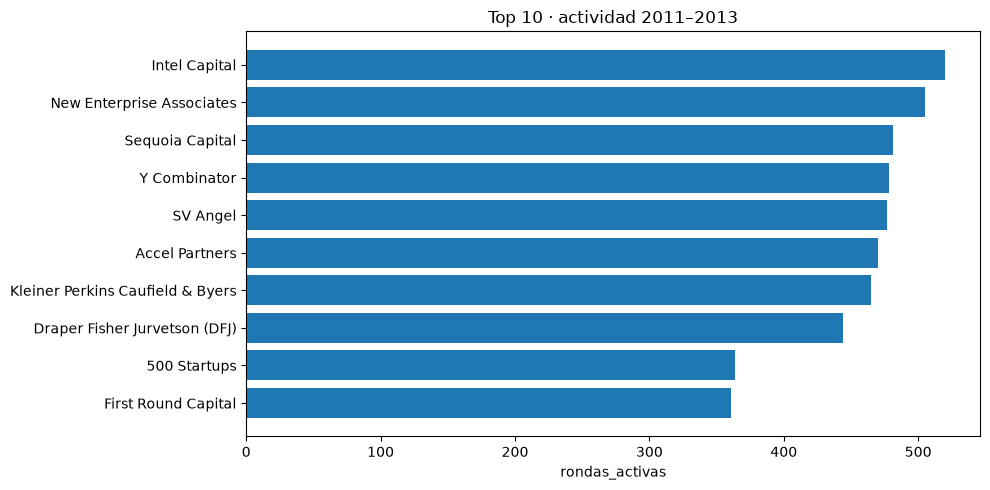

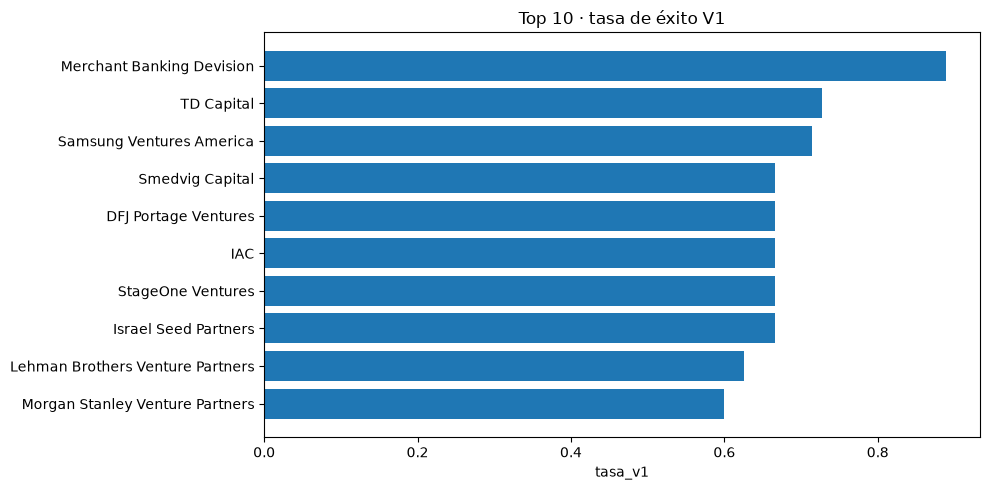

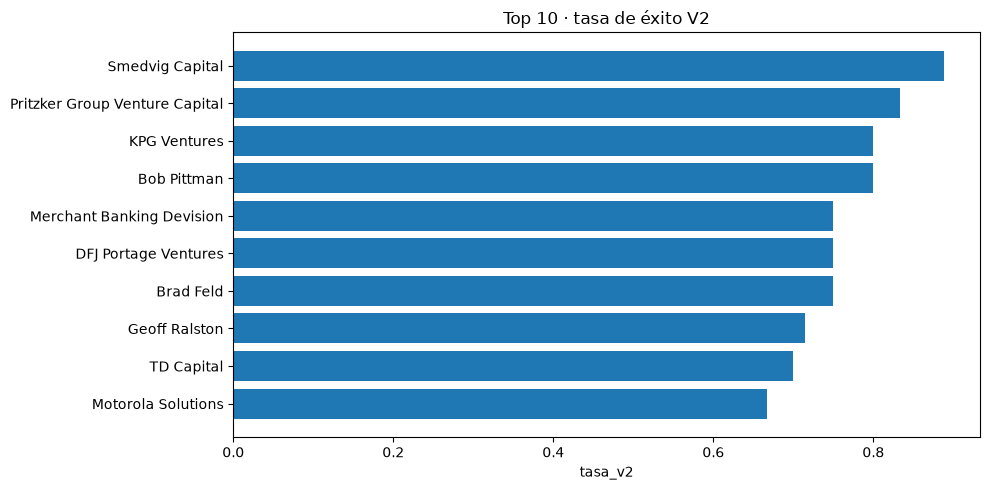

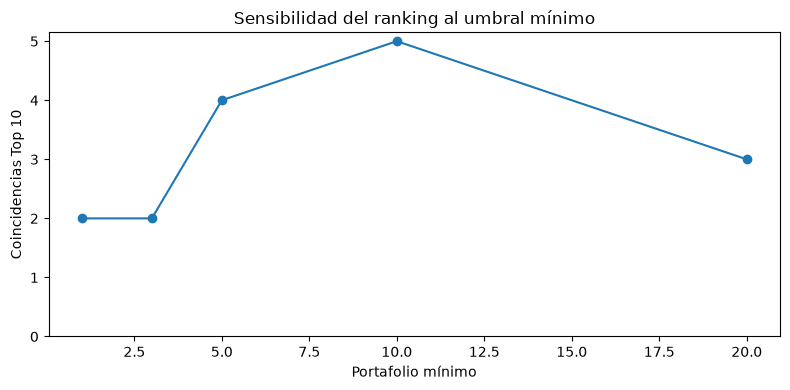

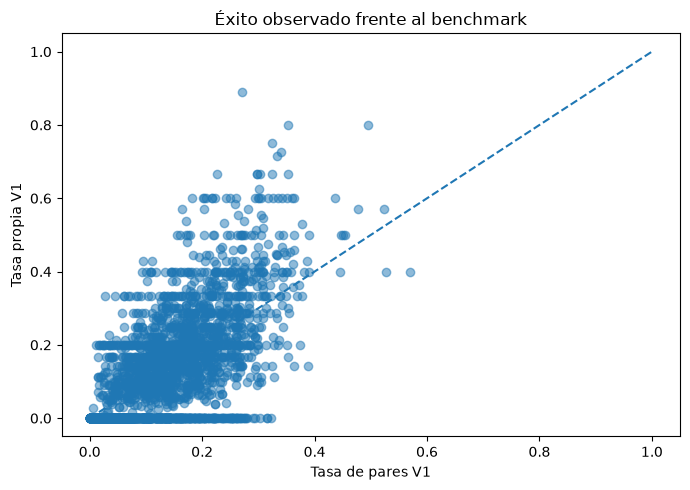

In [8]:
for df,campo,titulo in [
 (actividad.sort_values('rondas_activas',ascending=False).head(10),'rondas_activas','Top 10 · actividad 2011–2013'),
 (top1,'tasa_v1','Top 10 · tasa de éxito V1'),
 (top2,'tasa_v2','Top 10 · tasa de éxito V2')]:
    if df.empty:continue
    fig,ax=plt.subplots(figsize=(10,5))
    ax.barh(df.nombre.fillna(df.inversionista_id.astype(str)),df[campo])
    ax.invert_yaxis();ax.set_title(titulo);ax.set_xlabel(campo)
    plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(8,4));ax.plot(sensibilidad.minimo_portafolio,sensibilidad.coincidencias_top10,marker='o');ax.set(xlabel='Portafolio mínimo',ylabel='Coincidencias Top 10',title='Sensibilidad del ranking al umbral mínimo');ax.set_ylim(bottom=0);plt.tight_layout();plt.show()
comparacion=indicadores[(indicadores.n_empresas>=MIN_PORTAFOLIO)&indicadores.benchmark_tasa_v1.notna()]
if not comparacion.empty:
 fig,ax=plt.subplots(figsize=(7,5));ax.scatter(comparacion.benchmark_tasa_v1,comparacion.tasa_v1,alpha=.5);ax.plot([0,1],[0,1],linestyle='--');ax.set(xlabel='Tasa de pares V1',ylabel='Tasa propia V1',title='Éxito observado frente al benchmark');plt.tight_layout();plt.show()

## 9. Análisis exploratorio adicional: rondas posteriores
El notebook original también exploraba rondas posteriores como proxy de continuidad de financiamiento. **No se confunde con V2 oficial**: una ronda posterior no equivale a IPO/adquisición ni a retorno financiero.

In [9]:
rondas=con.execute("SELECT empresa_id,fecha FROM marts.fact_rondas WHERE fecha BETWEEN DATE '2005-01-01' AND DATE '2013-12-31' AND empresa_id IS NOT NULL").df()
rondas.fecha=pd.to_datetime(rondas.fecha)
posteriores=portafolio[['inversionista_id','empresa_id','primera_inversion']].merge(rondas,on='empresa_id',how='left')
posteriores['posterior']=posteriores.fecha>posteriores.primera_inversion
continuidad=posteriores.groupby(['inversionista_id','empresa_id'],as_index=False).posterior.max().groupby('inversionista_id',as_index=False).posterior.mean().rename(columns={'posterior':'tasa_empresas_con_ronda_posterior'})
print('Indicador exploratorio de seguimiento; no es definición oficial de éxito V2')
display(continuidad.sort_values('tasa_empresas_con_ronda_posterior',ascending=False).head(10))

Indicador exploratorio de seguimiento; no es definición oficial de éxito V2


,inversionista_id,tasa_empresas_con_ronda_posterior
11010,p:13207,1.0
10981,p:131181,1.0
10970,p:130806,1.0
3630,f:12727,1.0
3629,f:12726,1.0
10972,p:130835,1.0
10973,p:130851,1.0
10974,p:130944,1.0
10980,p:130987,1.0
10983,p:13125,1.0


## 10. Persistencia de resultados en `marts` (no CSV)
Se mantienen los nombres de las tres tablas acordadas con el equipo. Los resultados de sensibilidad se guardan en una cuarta tabla de apoyo. **El notebook debe ejecutarse después de `run_all.py` y antes de `publish_to_neon.py`.**

In [10]:
# Publicar en DuckDB. DuckDB registra DataFrames como vistas temporales para CREATE TABLE AS.
actividad_full=indicadores[['inversionista_id','nombre','tipo_inversionista','pais','n_empresas']].merge(actividad[['inversionista_id','rondas_activas','empresas_activas','primera_ronda','ultima_ronda']],on='inversionista_id',how='left')
actividad_full['activo_2005_2013']=actividad_full.rondas_activas.fillna(0)>0
actividad_full=actividad_full.merge(montos,on='inversionista_id',how='left')
exito_final=indicadores[['inversionista_id','n_empresas','exitos_v1','tasa_v1','elegibles_v2','exitos_v2','tasa_v2']].copy()
benchmark_final=indicadores[['inversionista_id','nombre','tipo_inversionista','pais','n_empresas','tasa_v1','tasa_v2','benchmark_tasa_v1','diferencia_pp','segmentos_comparables','segmentos_total']].copy()
benchmark_final['elegible_ranking']=benchmark_final.n_empresas>=MIN_PORTAFOLIO
# DuckDB 2.0 no permite register() si quedo un resultado sin consumir: fetchone()
# lee una sola fila y deja el resultado a medias, asi que la segunda vuelta del
# bucle fallaba con ResourceInUseException. Se consume todo con fetchall().
for nombre,df in [('res_inversionista_activo',actividad_full),('res_exito_inversionista',exito_final),('res_benchmark_inversionista',benchmark_final),('res_sensibilidad_inversionistas',sensibilidad)]:
    con.register('_resultado',df)
    con.execute(f'CREATE OR REPLACE TABLE marts.{nombre} AS SELECT * FROM _resultado').fetchall()
    n_filas=con.execute(f'SELECT COUNT(*) FROM marts.{nombre}').fetchall()[0][0]
    con.unregister('_resultado')
    print(nombre,n_filas,'filas')
assert con.execute('SELECT COUNT(*) FROM marts.res_exito_inversionista WHERE n_empresas=0').fetchall()[0][0]==0
assert con.execute('SELECT COUNT(*) FROM marts.res_exito_inversionista WHERE tasa_v1<0 OR tasa_v1>1 OR tasa_v2<0 OR tasa_v2>1').fetchall()[0][0]==0
assert con.execute('SELECT COUNT(*) FROM marts.res_exito_inversionista').fetchall()[0][0]==con.execute('SELECT COUNT(*) FROM marts.res_benchmark_inversionista').fetchall()[0][0]
print('✓ Resultados persistidos y controles básicos correctos')

res_inversionista_activo 16897 filas
res_exito_inversionista 16897 filas
res_benchmark_inversionista 16897 filas
res_sensibilidad_inversionistas 5 filas
✓ Resultados persistidos y controles básicos correctos


## 11. Hallazgos, interpretación y advertencias

In [11]:
print('PREGUNTA: ¿Cambia el Top 10 al variar la definición de éxito?')
print('MÉTODO: empresas únicas por inversionista; V1 = salida observada; '
      'V2 = salida a 5 años con cohortes maduras; universo común; benchmark ajustado.')
print(f'RESULTADO: {len(indicadores):,} inversionistas con portafolio 2005–2013.')
print(f'  Top V1: {len(top1)}; Top V2: {len(top2)}; '
      f'coincidencia: {coinciden}/{min(len(top1), len(top2))}.')
print(f'  Inversionistas con >= {MIN_PORTAFOLIO} empresas: '
      f'{(indicadores.n_empresas >= MIN_PORTAFOLIO).sum():,}.')
print(f'  Con >= {MIN_PORTAFOLIO} empresas elegibles V2: '
      f'{((indicadores.n_empresas >= MIN_PORTAFOLIO) & (indicadores.elegibles_v2 >= MIN_PORTAFOLIO)).sum():,}.')
if len(top1) and len(top2):
    print('INTERPRETACIÓN:', 'El ranking es idéntico bajo ambas métricas.'
          if coinciden == len(top1) == len(top2)
          else 'La selección de inversionistas cambia con la definición de éxito.')
print('ADVERTENCIA: las salidas no equivalen a retornos financieros; '
      'no se demuestra habilidad causal, y V1 sufre censura temporal.')
print('RECOMENDACIÓN: presentar V2 y V1 juntas y reportar la diferencia '
      'frente a pares comparables antes de seleccionar coinversionistas.')


PREGUNTA: ¿Cambia el Top 10 al variar la definición de éxito?
MÉTODO: empresas únicas por inversionista; V1 = salida observada; V2 = salida a 5 años con cohortes maduras; universo común; benchmark ajustado.
RESULTADO: 16,897 inversionistas con portafolio 2005–2013.
  Top V1: 10; Top V2: 10; coincidencia: 4/10.
  Inversionistas con >= 5 empresas: 2,346.
  Con >= 5 empresas elegibles V2: 919.
INTERPRETACIÓN: La selección de inversionistas cambia con la definición de éxito.
ADVERTENCIA: las salidas no equivalen a retornos financieros; no se demuestra habilidad causal, y V1 sufre censura temporal.
RECOMENDACIÓN: presentar V2 y V1 juntas y reportar la diferencia frente a pares comparables antes de seleccionar coinversionistas.


## 12. Limitaciones y reproducción
1. **Cobertura:** Crunchbase registra pocas rondas antes de 2005; el análisis principal empieza en 2005.
2. **Censura:** la base termina en 2013. Las inversiones recientes no han tenido cinco años para observar una salida; por eso V2 excluye cohortes inmaduras.
3. **Selección:** el registro de startups, rondas y salidas no es exhaustivo ni aleatorio.
4. **Benchmark:** industria, etapa y cohorte ayudan a comparar, pero no eliminan factores no observados. Etapa es la registrada por la dimensión (puede reflejar información posterior a la inversión).
5. **Tamaño de muestra:** una tasa sobre pocas empresas es inestable; el umbral de 5 es una regla práctica y se prueba su sensibilidad.
6. **Financiamiento:** el peso del puente distribuye monto registrado; no es aporte efectivo de cada inversionista.
7. **Interpretación:** V1 y V2 son indicadores de salidas observadas, no rentabilidad ni prueba de causalidad.

**Orden:** `python run_all.py` → notebooks (incluido este) → `python publish/publish_to_neon.py`. El publicador debe contemplar las nuevas tablas y sus claves. No se publica automáticamente al ejecutar este notebook. El profesor permite apoyo de IA con declaración explícita de su uso.

## 13. Solicitud de cambio del profesor — trazabilidad

La Parte 4 exige documentar la **pregunta nueva publicada el 22 de octubre**.
Este notebook ya incorpora `tipo_inversionista` y `pais` desde
`marts.dim_inversionista` en sus tablas de salida, de modo que es posible
segmentar el dashboard por tipo sin rehacer el pipeline.

**Pendiente de validación con el equipo:** transcribir literalmente la solicitud
real del profesor, describir qué cambió en el modelo y en las métricas, y registrar
el PR correspondiente. No se debe afirmar que esta sección responde a una
solicitud cuyo enunciado exacto todavía no se ha proporcionado.

## 14. Declaración breve de uso de IA

Se utilizó ChatGPT como apoyo para revisar código Python/SQL, estructurar el
análisis y documentar métricas. El equipo debe verificar la ejecución, los
resultados y su interpretación antes de la entrega y la defensa.


# ANEXO — Notebook original preservado (gráficas y resultados históricos)

A continuación se conserva el contenido del archivo original que subiste, incluidas sus tablas y **tres gráficas guardadas**. **No ejecutes las celdas de este anexo**: contienen código anterior que usa `clean` y podría fallar. El análisis actualizado se encuentra arriba.

# Entrega final · Analista de inversiones
Basado en el notebook anterior, con las métricas **requeridas en el reparto**. Usa `clean.investments` + `clean.funding_rounds` como fuente de respaldo cuando los marts de Cristina aún no están cargados.

**Importante:** no confunde que una celda termine sin error con que existan resultados. Si no hay participaciones, detiene la ejecución con un diagnóstico. No modifica la base.

**Definiciones:** activo = al menos una ronda entre 2011 y 2013; éxito V1 = IPO o adquisición después de primera participación hasta 2013; éxito V2 = ronda posterior de la empresa; benchmark por industria, etapa y cohorte; portafolio mínimo = 5 empresas (editable).


**Corrección de compatibilidad:** se detectan `company_id` y las claves disponibles en cada tabla. Los nombres de inversionistas son opcionales; se usa el ID cuando no hay dimensión con nombres. Si faltan datos imprescindibles, se muestra un error explícito.

## 1 · Conexión y revisión de fuentes

In [12]:
from pathlib import Path
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
MIN_PORTAFOLIO = 5
INICIO, CORTE = '2011-01-01', '2013-12-31'
RUTA_DB = ''  # Solo si la detección automática no encuentra tu base
candidatas = [Path(RUTA_DB)] if RUTA_DB else []
for x in [Path.cwd(), *Path.cwd().parents, Path.home()/'proyectofinal'/'proyecto_bi_codigo_ligero'/'proyecto_bi_crunchbase']:
    candidatas += [x/'data'/'crunchbase.duckdb', x/'build'/'crunchbase.duckdb', x/'crunchbase.duckdb']
DB = next((x for x in candidatas if x.is_file()), None)
if DB is None:
    raise FileNotFoundError('No se encontró build/crunchbase.duckdb. Escribí la ruta en RUTA_DB.')
# La parte principal dejo abierta una conexion de lectura-escritura al mismo
# archivo; DuckDB no permite reabrirlo en solo-lectura sin cerrarla antes.
try:
    con.close()
except NameError:
    pass
con=duckdb.connect(str(DB),read_only=True)
print('BASE:',DB)
display(con.execute("SELECT table_schema,table_name FROM information_schema.tables WHERE table_schema IN ('clean','marts') ORDER BY 1,2").df())
def tiene(schema,table):
    return con.execute('SELECT COUNT(*) FROM information_schema.tables WHERE table_schema=? AND table_name=?',[schema,table]).fetchone()[0]>0
def cols(schema,table):
    return set(con.execute(f'SELECT * FROM {schema}.{table} LIMIT 0').df().columns)
def columna(schema,table,opciones,required=True):
    x=next((a for a in opciones if a in cols(schema,table)),None)
    if required and not x: raise ValueError(f'Falta columna en {schema}.{table}: {opciones}. Disponibles: {cols(schema,table)}')
    return x


BASE: /Users/robertomejia/Proyectos/crunchbase-bi-proyecto-final/data/crunchbase.duckdb


,table_schema,table_name
0,clean,acquisitions
1,clean,degrees
2,clean,funding_rounds
3,clean,funds
4,clean,investments
5,clean,ipos
6,clean,milestones
7,clean,objects
8,clean,offices
9,clean,people


if not (tiene('clean','investments') and tiene('clean','funding_rounds')):
    raise RuntimeError('Faltan clean.investments o clean.funding_rounds. Ejecutá el pipeline del proyecto.')
ic=cols('clean','investments'); rc=cols('clean','funding_rounds')
print('Inversiones:',con.execute('SELECT count(*) FROM clean.investments').fetchone()[0])
print('Rondas:',con.execute('SELECT count(*) FROM clean.funding_rounds').fetchone()[0])
i_id=columna('clean','investments',['investor_object_id','investor_id','inversionista_id'])
i_ronda=columna('clean','investments',['funding_round_id','ronda_id'])
r_id=columna('clean','funding_rounds',['funding_round_id','ronda_id'])
r_empresa=columna('clean','funding_rounds',['company_id','object_id','empresa_id'])
r_fecha=columna('clean','funding_rounds',['funded_at','fecha'])
participaciones=con.execute(f'''
SELECT DISTINCT i."{i_id}" AS inversionista_id, r."{r_id}" AS ronda_id,
       r."{r_empresa}" AS empresa_id, TRY_CAST(r."{r_fecha}" AS DATE) AS fecha
FROM clean.investments i
JOIN clean.funding_rounds r ON i."{i_ronda}"=r."{r_id}"
WHERE i."{i_id}" IS NOT NULL AND r."{r_empresa}" IS NOT NULL
AND TRY_CAST(r."{r_fecha}" AS DATE)<=DATE '2013-12-31'
''').df()
participaciones['fecha']=pd.to_datetime(participaciones.fecha)
print('Participaciones válidas:',len(participaciones))
if participaciones.empty:
    raise RuntimeError('No hay participaciones con estas claves y fechas; revisar el origen antes de calcular.')
display(participaciones.head())


In [13]:
ic=cols('clean','investments'); rc=cols('clean','funding_rounds')
print('Filas inversiones:',con.execute('SELECT COUNT(*) FROM clean.investments').fetchone()[0])
print('Filas rondas:',con.execute('SELECT COUNT(*) FROM clean.funding_rounds').fetchone()[0])
i_inv=columna('clean','investments',['investor_object_id','investor_id'])
i_ronda=columna('clean','investments',['funding_round_id','ronda_id'])
r_ronda=columna('clean','funding_rounds',['funding_round_id','ronda_id'])
r_empresa=columna('clean','funding_rounds',['company_id','object_id','empresa_id'])
r_fecha=columna('clean','funding_rounds',['funded_at','fecha'])
participaciones=con.execute(f"""SELECT DISTINCT i."{i_inv}" AS inversionista_id, r."{r_ronda}" AS ronda_id,
r."{r_empresa}" AS empresa_id, TRY_CAST(r."{r_fecha}" AS DATE) AS fecha
FROM clean.investments i JOIN clean.funding_rounds r ON i."{i_ronda}"=r."{r_ronda}"
WHERE i."{i_inv}" IS NOT NULL AND r."{r_empresa}" IS NOT NULL
AND TRY_CAST(r."{r_fecha}" AS DATE)<=DATE '2013-12-31'""").df()
participaciones['fecha']=pd.to_datetime(participaciones.fecha)
print('Participaciones:',len(participaciones))
if participaciones.empty:raise RuntimeError('No hay participaciones: revisar las llaves y fechas.')
display(participaciones.head())

Filas inversiones: 80902
Filas rondas: 52928
Participaciones: 80703


,inversionista_id,ronda_id,empresa_id,fecha
0,f:66,81,c:96,2007-02-27
1,f:89,111,c:128,2007-01-01
2,f:110,140,c:162,2006-04-01
3,f:118,148,c:170,2006-02-01
4,f:123,159,c:179,2002-12-01


# Los nombres se obtienen de la dimensión oficial solo cuando las columnas coinciden.
ids=participaciones.inversionista_id.drop_duplicates()
nombres=pd.DataFrame({'inversionista_id':ids})
nombres['nombre']=nombres.inversionista_id.astype(str)
if tiene('marts','dim_inversionista'):
    s='marts';t='dim_inversionista'
    nid=columna(s,t,['inversionista_id','investor_object_id','investor_id'],False)
    nn=columna(s,t,['nombre','name'],False)
    if nid and nn:
        nombres=con.execute(f'SELECT DISTINCT "{nid}" AS inversionista_id, "{nn}" AS nombre FROM marts.dim_inversionista').df()
elif tiene('clean','objects'):
    s='clean';t='objects'
    nid=columna(s,t,['object_id','id','company_id'],False)
    nn=columna(s,t,['name','nombre'],False)
    if nid and nn:
        nombres=con.execute(f'SELECT DISTINCT "{nid}" AS inversionista_id, "{nn}" AS nombre FROM clean.objects').df()
act=participaciones[participaciones.fecha.between(INICIO,CORTE)]
actividad=act.groupby('inversionista_id',as_index=False).agg(
    rondas_activas=('ronda_id','nunique'),empresas_activas=('empresa_id','nunique'))
actividad=actividad.merge(nombres.drop_duplicates('inversionista_id'),on='inversionista_id',how='left')
actividad['nombre']=actividad['nombre'].fillna(actividad.inversionista_id.astype(str))
print('Inversionistas activos:',len(actividad))
display(actividad.sort_values('rondas_activas',ascending=False).head(20))


In [14]:
nombres=pd.DataFrame({'inversionista_id':participaciones.inversionista_id.unique()})
nombres['nombre']=nombres.inversionista_id.astype(str)
for s,t in [('marts','dim_inversionista'),('clean','objects')]:
    if tiene(s,t):
        ni=columna(s,t,['inversionista_id','object_id','id'],False)
        nn=columna(s,t,['nombre','name'],False)
        if ni and nn:
            nombres=con.execute(f'SELECT DISTINCT "{ni}" AS inversionista_id, "{nn}" AS nombre FROM "{s}"."{t}"').df()
            break
act=participaciones[participaciones.fecha.between(INICIO,CORTE)]
actividad=act.groupby('inversionista_id',as_index=False).agg(rondas_activas=('ronda_id','nunique'),empresas_activas=('empresa_id','nunique'))
actividad=actividad.merge(nombres.drop_duplicates('inversionista_id'),on='inversionista_id',how='left')
actividad['nombre']=actividad.nombre.fillna(actividad.inversionista_id.astype(str))
print('Inversionistas activos:',len(actividad))
display(actividad.sort_values('rondas_activas',ascending=False).head(20))

Inversionistas activos: 11550


,inversionista_id,rondas_activas,empresas_activas,nombre
4880,f:5928,316,279,500 Startups
4061,f:3181,301,273,SV Angel
897,c:2520,290,278,Y Combinator
4054,f:316,259,197,New Enterprise Associates
4378,f:41,239,178,Kleiner Perkins Caufield & Byers
1243,c:362,228,207,Techstars
4042,f:3127,215,172,Andreessen Horowitz
4345,f:4,212,170,Accel Partners
3638,f:2195,201,156,Google Ventures
4237,f:367,197,160,Intel Capital


portafolio=participaciones.groupby(['inversionista_id','empresa_id'],as_index=False).agg(primera_inversion=('fecha','min'))
rondas=con.execute(f'''SELECT "{r_empresa}" AS empresa_id, TRY_CAST("{r_fecha}" AS DATE) AS fecha
FROM clean.funding_rounds WHERE TRY_CAST("{r_fecha}" AS DATE)<=DATE '2013-12-31' ''').df()
rondas.fecha=pd.to_datetime(rondas.fecha)
salidas_partes=[]
fuentes=[]
for tabla,ids,fechas in [
    ('ipos',['company_id','object_id','empresa_id'],['public_at','fecha']),
    ('acquisitions',['acquired_company_id','acquired_object_id','empresa_adquirida_id'],['acquired_at','fecha'])]:
    if tiene('clean',tabla):
        ident=columna('clean',tabla,ids,False)
        fecha=columna('clean',tabla,fechas,False)
        if ident and fecha:
            temp=con.execute(f'SELECT "{ident}" AS empresa_id,TRY_CAST("{fecha}" AS DATE) AS fecha FROM clean."{tabla}"').df()
            salidas_partes.append(temp)
            fuentes.append(tabla)
        else: print('ADVERTENCIA: columnas no reconocidas en',tabla,cols('clean',tabla))
    else: print('ADVERTENCIA: no existe clean.'+tabla)
if not salidas_partes:
    raise RuntimeError('No hay fuentes válidas de IPO/adquisición. No podemos calcular V1.')
salidas=pd.concat(salidas_partes,ignore_index=True)
salidas.fecha=pd.to_datetime(salidas.fecha)
salidas=salidas[salidas.fecha.le(pd.Timestamp(CORTE))]
def fechas_por_empresa(df):
    return {k:g.fecha.dropna().to_numpy(dtype='datetime64[ns]') for k,g in df.groupby('empresa_id')}
fr=fechas_por_empresa(rondas); fs=fechas_por_empresa(salidas)
def posterior(mapa,empresa,fecha,estricto):
    arr=mapa.get(empresa)
    if arr is None or pd.isna(fecha):return False
    return bool(np.any(arr>np.datetime64(fecha) if estricto else arr>=np.datetime64(fecha)))
portafolio['exito_v1']=portafolio.apply(lambda x:posterior(fs,x.empresa_id,x.primera_inversion,False),axis=1)
portafolio['exito_v2']=portafolio.apply(lambda x:posterior(fr,x.empresa_id,x.primera_inversion,True),axis=1)
portafolio['cohorte']=portafolio.primera_inversion.dt.year
indicadores=portafolio.groupby('inversionista_id',as_index=False).agg(
    n_empresas=('empresa_id','nunique'),exitos_v1=('exito_v1','sum'),exitos_v2=('exito_v2','sum'))
indicadores['tasa_v1']=indicadores.exitos_v1/indicadores.n_empresas
indicadores['tasa_v2']=indicadores.exitos_v2/indicadores.n_empresas
indicadores=indicadores.merge(nombres.drop_duplicates('inversionista_id'),on='inversionista_id',how='left')
indicadores['nombre']=indicadores.nombre.fillna(indicadores.inversionista_id.astype(str))
elegibles=indicadores[indicadores.n_empresas>=MIN_PORTAFOLIO].copy()
print('Portafolios:',len(indicadores),'| Elegibles:',len(elegibles),'| Salidas disponibles:',fuentes)
if len(fuentes)<2:print('⚠ V1 parcial: falta una de las fuentes de salida.')
display(indicadores.sort_values('n_empresas',ascending=False).head(15))


In [15]:
portafolio=participaciones.groupby(['inversionista_id','empresa_id'],as_index=False).agg(primera_inversion=('fecha','min'))
rondas=con.execute(f"""SELECT "{r_empresa}" AS empresa_id,TRY_CAST("{r_fecha}" AS DATE) AS fecha FROM clean.funding_rounds WHERE TRY_CAST("{r_fecha}" AS DATE)<=DATE '2013-12-31'""").df()
rondas.fecha=pd.to_datetime(rondas.fecha)
salidas=[]
for tabla,ids,fechas in [('ipos',['company_id','object_id','empresa_id'],['public_at','fecha']),('acquisitions',['acquired_company_id','acquired_object_id','empresa_adquirida_id'],['acquired_at','fecha'])]:
    if not tiene('clean',tabla):
        print('Advertencia: falta clean.'+tabla);continue
    ci=columna('clean',tabla,ids,False);cf=columna('clean',tabla,fechas,False)
    if ci and cf:
        salidas.append(con.execute(f'SELECT "{ci}" AS empresa_id,TRY_CAST("{cf}" AS DATE) AS fecha FROM clean."{tabla}"').df())
    else: print('Advertencia: columnas no reconocidas en',tabla,cols('clean',tabla))
if not salidas:raise RuntimeError('No se encontraron tablas/columnas para calcular IPO y adquisiciones.')
salidas=pd.concat(salidas,ignore_index=True)
salidas.fecha=pd.to_datetime(salidas.fecha)
salidas=salidas[salidas.fecha.le(pd.Timestamp(CORTE))]
def mapa_fechas(df):return {k:g.fecha.dropna().to_numpy(dtype='datetime64[ns]') for k,g in df.groupby('empresa_id')}
fr=mapa_fechas(rondas);fs=mapa_fechas(salidas)
def tiene_evento(mapa,empresa,fecha,estricto=True):
    arr=mapa.get(empresa)
    if arr is None or pd.isna(fecha):return False
    return bool(np.any(arr>np.datetime64(fecha) if estricto else arr>=np.datetime64(fecha)))
portafolio['exito_v1']=portafolio.apply(lambda x:tiene_evento(fs,x.empresa_id,x.primera_inversion,False),axis=1)
portafolio['exito_v2']=portafolio.apply(lambda x:tiene_evento(fr,x.empresa_id,x.primera_inversion,True),axis=1)
portafolio['cohorte']=portafolio.primera_inversion.dt.year
indicadores=portafolio.groupby('inversionista_id',as_index=False).agg(n_empresas=('empresa_id','nunique'),exitos_v1=('exito_v1','sum'),exitos_v2=('exito_v2','sum'))
indicadores['tasa_v1']=indicadores.exitos_v1/indicadores.n_empresas
indicadores['tasa_v2']=indicadores.exitos_v2/indicadores.n_empresas
indicadores=indicadores.merge(nombres.drop_duplicates('inversionista_id'),on='inversionista_id',how='left')
indicadores['nombre']=indicadores.nombre.fillna(indicadores.inversionista_id.astype(str))
elegibles=indicadores[indicadores.n_empresas>=MIN_PORTAFOLIO].copy()
print('Portafolios:',len(indicadores),'| Elegibles:',len(elegibles))
if len(salidas)<2:print('ADVERTENCIA: V1 parcial, falta una fuente de salida.')
display(indicadores.sort_values('n_empresas',ascending=False).head(15))

Portafolios: 17122 | Elegibles: 2363


,inversionista_id,n_empresas,exitos_v1,exitos_v2,tasa_v1,tasa_v2,nombre
1142,c:2520,459,64,163,0.139434,0.355120,Y Combinator
5913,f:3181,441,114,230,0.258503,0.521542,SV Angel
6318,f:367,383,72,171,0.187990,0.446475,Intel Capital
5893,f:316,321,57,178,0.177570,0.554517,New Enterprise Associates
8148,f:5928,315,31,96,0.098413,0.304762,500 Startups
4663,f:17,309,75,164,0.242718,0.530744,Sequoia Capital
6555,f:4,289,65,156,0.224913,0.539792,Accel Partners
5379,f:26,273,58,148,0.212454,0.542125,Draper Fisher Jurvetson (DFJ)
6630,f:41,271,44,167,0.162362,0.616236,Kleiner Perkins Caufield & Byers
1634,c:362,268,29,154,0.108209,0.574627,Techstars


# Segmentación: nombres de columnas se detectan antes de consultar.
if tiene('marts','dim_empresa'):
    s,t='marts','dim_empresa'
else:
    s,t='clean','objects'
if tiene(s,t):
    cid=columna(s,t,['empresa_id','company_id','object_id','id'],False)
    ci=columna(s,t,['industria','categoria_principal','category_code','categoria'],False)
    ce=columna(s,t,['etapa','etapa_empresa','status'],False)
    if cid:
        ii=f'"{ci}"' if ci else "'sin_dato'"
        ee=f'"{ce}"' if ce else "'sin_dato'"
        segmentos=con.execute(f'SELECT "{cid}" AS empresa_id,{ii} AS industria,{ee} AS etapa FROM "{s}"."{t}"').df()
    else:
        segmentos=pd.DataFrame({'empresa_id':portafolio.empresa_id.unique(),'industria':'sin_dato','etapa':'sin_dato'})
else:
    segmentos=pd.DataFrame({'empresa_id':portafolio.empresa_id.unique(),'industria':'sin_dato','etapa':'sin_dato'})
b=portafolio.merge(segmentos.drop_duplicates('empresa_id'),on='empresa_id',how='left')
b[['industria','etapa']]=b[['industria','etapa']].fillna('sin_dato')
benchmark=b.groupby(['industria','etapa','cohorte'],dropna=False).agg(
    pares=('empresa_id','size'),empresas=('empresa_id','nunique'),inversionistas=('inversionista_id','nunique'),
    tasa_v1=('exito_v1','mean'),tasa_v2=('exito_v2','mean')).reset_index()
display(benchmark.sort_values('pares',ascending=False).head(20))


In [16]:
if tiene('marts','dim_empresa'):s,t='marts','dim_empresa'
else:s,t='clean','objects'
if tiene(s,t):
    ci=columna(s,t,['empresa_id','company_id','object_id','id'],False)
    ind=columna(s,t,['industria','categoria_principal','category_code','categoria'],False)
    eta=columna(s,t,['etapa','etapa_empresa','status'],False)
    if ci:
        segmentos=con.execute(f'SELECT "{ci}" AS empresa_id,'+(f'"{ind}"' if ind else "'sin_dato'")+' AS industria,'+(f'"{eta}"' if eta else "'sin_dato'")+f' AS etapa FROM "{s}"."{t}"').df()
    else:segmentos=pd.DataFrame({'empresa_id':portafolio.empresa_id.unique(),'industria':'sin_dato','etapa':'sin_dato'})
else:segmentos=pd.DataFrame({'empresa_id':portafolio.empresa_id.unique(),'industria':'sin_dato','etapa':'sin_dato'})
b=portafolio.merge(segmentos.drop_duplicates('empresa_id'),on='empresa_id',how='left')
b[['industria','etapa']]=b[['industria','etapa']].fillna('sin_dato')
benchmark=b.groupby(['industria','etapa','cohorte'],dropna=False).agg(pares=('empresa_id','size'),empresas=('empresa_id','nunique'),inversionistas=('inversionista_id','nunique'),tasa_v1=('exito_v1','mean'),tasa_v2=('exito_v2','mean')).reset_index()
display(benchmark.sort_values('pares',ascending=False).head(20))

,industria,etapa,cohorte,pares,empresas,inversionistas,tasa_v1,tasa_v2
1142,mobile,angel,2012,552,181,469,0.115942,0.300725
2019,software,angel,2013,487,241,398,0.002053,0.102669
2096,software,venture,2006,457,226,368,0.234136,0.446389
2218,web,angel,2013,437,197,377,0.000000,0.048055
2062,software,series-a,2013,424,166,366,0.000000,0.101415
2217,web,angel,2012,405,194,327,0.037037,0.180247
1178,mobile,series-a,2013,402,125,352,0.000000,0.039801
444,ecommerce,series-a,2013,386,110,342,0.000000,0.134715
412,ecommerce,angel,2013,385,172,329,0.002597,0.059740
2216,web,angel,2011,360,148,291,0.258333,0.213889


## 6 · Sensibilidad de TOP 10 y tamaño mínimo

In [17]:
def comparar(umbral):
    e=indicadores[indicadores.n_empresas>=umbral]
    t1=e.sort_values(['tasa_v1','n_empresas','inversionista_id'],ascending=[False,False,True]).head(10)
    t2=e.sort_values(['tasa_v2','n_empresas','inversionista_id'],ascending=[False,False,True]).head(10)
    return t1,t2,len(set(t1.inversionista_id)&set(t2.inversionista_id))
top1,top2,coinciden=comparar(MIN_PORTAFOLIO)
print('TOP 10 V1');display(top1[['nombre','n_empresas','tasa_v1']])
print('TOP 10 V2');display(top2[['nombre','n_empresas','tasa_v2']])
print('Coinciden:',coinciden,'de',min(len(top1),len(top2)))
sensibilidad=pd.DataFrame([{'minimo_empresas':k,'elegibles':int((indicadores.n_empresas>=k).sum()),'coincidencias_top10':comparar(k)[2]} for k in [1,3,5,10,20]])
display(sensibilidad)


TOP 10 V1


,nombre,n_empresas,tasa_v1
5732,Merchant Banking Devision,9,0.888889
9920,i-Hatch Ventures,6,0.833333
1584,NEC,5,0.800000
1614,AOL,5,0.800000
14018,Brian Pokorny,12,0.750000
8088,Israel Seed Partners,8,0.750000
6744,TD Capital,11,0.727273
6636,Samsung Ventures America,7,0.714286
9039,DFJ Portage Ventures,9,0.666667
1604,IAC,6,0.666667


TOP 10 V2


,nombre,n_empresas,tasa_v2
4608,Long River Ventures,8,1.0
5610,PTV Sciences,7,1.0
8132,Arcturus Capital,7,1.0
14857,Alex Hoye,7,1.0
3536,Coriolis Ventures,6,1.0
14743,Angus Davis,6,1.0
1614,AOL,5,1.0
1933,ABB,5,1.0
5036,Portview Communications Partners,5,1.0
5411,Altitude Life Science Ventures,5,1.0


Coinciden: 1 de 10


,minimo_empresas,elegibles,coincidencias_top10
0,1,17122,0
1,3,3824,1
2,5,2363,1
3,10,1206,1
4,20,559,1


## 7 · Gráficas y exportación

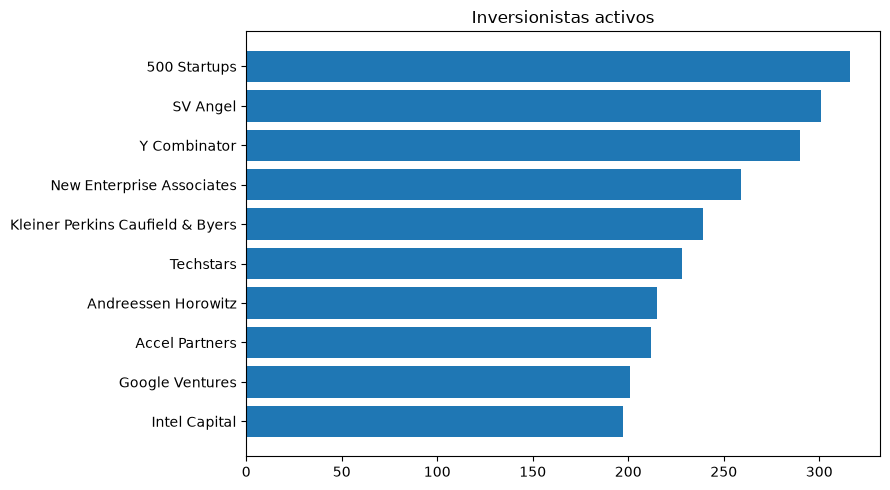

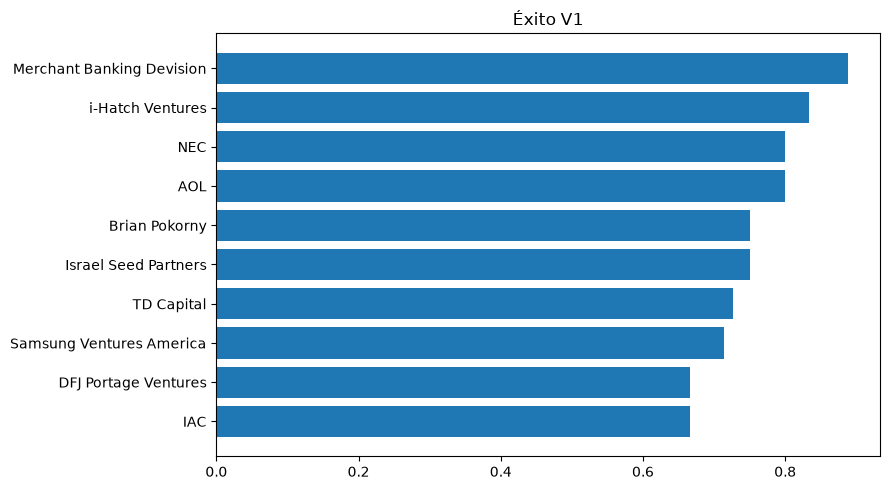

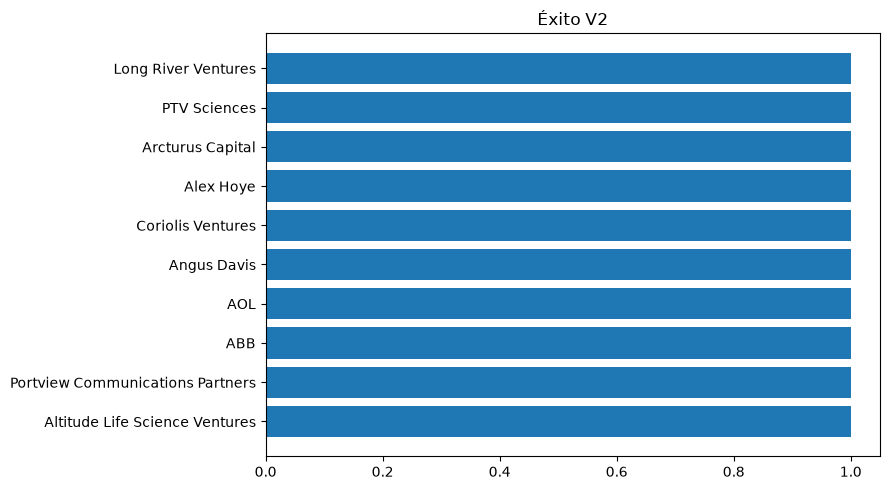

✓ Archivos exportados a /Users/robertomejia/Proyectos/crunchbase-bi-proyecto-final/notebooks/resultados_analista_inversiones
⚠ Éxito = proxy, no rentabilidad; observación limitada a 2013.


In [18]:
for df,campo,titulo in [(actividad.sort_values('rondas_activas',ascending=False).head(10),'rondas_activas','Inversionistas activos'),
                          (top1,'tasa_v1','Éxito V1'),(top2,'tasa_v2','Éxito V2')]:
    if df.empty: continue
    fig,ax=plt.subplots(figsize=(9,5))
    ax.barh(df.nombre.fillna(df.inversionista_id.astype(str)),df[campo])
    ax.invert_yaxis();ax.set_title(titulo);plt.tight_layout();plt.show()
SALIDA=Path.cwd()/'resultados_analista_inversiones'
SALIDA.mkdir(parents=True,exist_ok=True)
for nombre,df in [('actividad',actividad),('indicadores',indicadores),('benchmark',benchmark),('sensibilidad',sensibilidad)]:
    df.to_csv(SALIDA/f'{nombre}.csv',index=False)
print('✓ Archivos exportados a',SALIDA)
print('⚠ Éxito = proxy, no rentabilidad; observación limitada a 2013.')
